## ShortTerm Memory Using Persistance

In [13]:
from langgraph.graph import StateGraph , START,END
from typing import TypedDict
from langchain_core.messages import BaseMessage , HumanMessage
from langchain_mistralai import ChatMistralAI
from langgraph.checkpoint.memory import MemorySaver
from dotenv import load_dotenv

In [14]:
load_dotenv()

llm = ChatMistralAI(model="ministral-3b-latest", temperature=0.7)

In [15]:
class JokeState(TypedDict):
    topic:str
    joke:str
    explanation:str


In [21]:
def jokegenerated(state:JokeState):
    topic  = state['topic']
    joke = llm.invoke(f"Gerate a joke on the topic {topic}").content
    return {'joke':joke}

In [22]:
def explanation(state:JokeState):
    joke = state['joke']
    explanation = llm.invoke(f"explain this joke in 2 points: {joke}").content
    return {'explanation':explanation}

In [18]:
graph = StateGraph(JokeState)
graph.add_node('JokeGenerated' , jokegenerated)
graph.add_node('Explanation' , explanation)

graph.add_edge(START,'JokeGenerated')
graph.add_edge('JokeGenerated','Explanation')
graph.add_edge('Explanation',END)

checkpointer = MemorySaver()
joker = graph.compile(checkpointer=checkpointer)

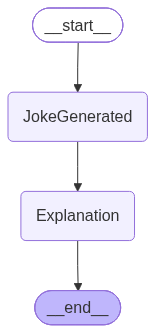

In [19]:
joker

In [24]:
config ={"configurable":{"thread_id": "user-1"}}
joker.invoke({'topic':'pizza'},config=config)

{'topic': 'pizza',
 'joke': AIMessage(content='Here’s a pizza-themed joke for you:\n\n**Why did the pizza go to therapy?**\nBecause it had too many *slices* of a problem!\n\n*(Bonus groan: The therapist said, "Just take a deep breath… and maybe a side of cheese.")* 🍕😆', additional_kwargs={}, response_metadata={'token_usage': {'prompt_tokens': 11, 'total_tokens': 75, 'completion_tokens': 64, 'prompt_tokens_details': {'cached_tokens': 0}, 'completion_tokens_details': {'reasoning_tokens': 0}, 'service_tier': 'standard'}, 'model_name': 'ministral-3b-latest', 'model': 'ministral-3b-latest', 'finish_reason': 'stop', 'model_provider': 'mistralai'}, id='lc_run--01a15a55-1cb5-7532-a418-b68c8542534f-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 11, 'output_tokens': 64, 'total_tokens': 75}),
 'explanation': AIMessage(content='Here’s the joke broken down in **two key points**:\n\n1. **Pun on "slices"**\n   - The joke plays on the word *"slices"* (both as a literal pizza